# NYC Taxi — Öğrenci 3 ders gösterimi

Ocak–Mayıs 2026 dönemindeki **17.210.961 temiz Yellow Taxi biniş kaydını** inceledik. Her kayıt bir yolculuğu temsil eder. Saat ve tarihler New York yerel saatidir.

**İçerik** · [Saat](#Saat) · [Gün](#Gün) · [Bölge](#Bölge) · [Ödeme](#Ödeme) · [Sonuç kontrolü](#Sonuç-kontrolü)

**Hocanın istediği iki çözüm:** Birincisi PySpark, ikincisi Spark'sız Python. İkinci çözümde **PyArrow Parquet dosyalarını okur**, **pandas gruplama, birleştirme ve pencere hesaplarını yapar**. Bu kütüphaneler Spark'sız uygulama için seçildi.

Her bölüm bir bulguyla başlar. Ardından aynı işi yapan gerçek PySpark ve pandas kodları görülür. İki yöntem de aynı beş temiz Parquet dosyasını ve TLC bölge sözlüğünü kullanır.

Sınıf gösterimi için grafikler ve sonuçlar notebook’a kaydedildi. [25 Nisan karşılaştırması](#pik-gun-kontrolu) doğrudan açılabilir.

**Teslim dosyası.** Öğrenci 3 için değerlendirilecek dosya bu notebook’tur. Tablolar ve grafikler kayıtlıdır. Yeniden çalıştırmak için notebook’u ekip deposunun `notebooks` klasöründen, projenin Python ortamıyla açın.

In [1]:
import inspect
import os
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))
from src import aggregate_trips as spark_queries
from src import compare_aggregation as kiyas
from src.config import FIGURES_DIR
from src.spark_session import get_spark

figures = FIGURES_DIR
BLUE, ORANGE = "#245B83", "#B34F27"
plt.rcParams.update({"font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.axisbelow": True, "grid.color": "#E1E6EB"})

def tr_int(value):
    return f"{value:,.0f}".replace(",", ".")

def tr_dec(value, digits=2):
    return f"{value:.{digits}f}".replace(".", ",")

def show_figure(fig, filename=None):
    plt.show()
    plt.close(fig)

def sorgulari_goster(spark_functions, pandas_functions):
    for title, functions in (("PySpark", spark_functions), ("pandas", pandas_functions)):
        listing = "\n\n".join(inspect.getsource(function).strip() for function in functions)
        display(Markdown(f"**{title}**\n\n```python\n{listing}\n```"))

os.environ.setdefault("NYC_JAVA_HOME", os.environ.get("JAVA_HOME", r"C:\tools\jdk-17"))
os.environ.setdefault("HADOOP_HOME", str(root / ".venv-tools" / "hadoop"))
spark = get_spark("ogrenci-3-tam-kiyas", driver_memory="3g", cores="2")
try:
    spark.sparkContext.setLogLevel("ERROR")
    assert spark.sparkContext.master == "local[2]"
    files = kiyas.clean_parquet_files()
    with kiyas.arrow_workers():
        spark_tables, _ = kiyas.spark_reports(spark, files, kiyas.ZONE_LOOKUP_PATH)
        pandas_tables, _ = kiyas.pandas_reports(files, kiyas.ZONE_LOOKUP_PATH)
        kiyas.verify_full_scope(spark_tables)
        kiyas.verify_reports(spark_tables, pandas_tables)
    spark_plan = kiyas.hourly_spark_plan(spark)
    saturdays = kiyas.saturday_context(spark)
finally:
    spark.stop()

hour = spark_tables["hour"]
day = spark_tables["day"].assign(pickup_date=lambda x: pd.to_datetime(x["pickup_date"]))
zone = spark_tables["zone"]
payment = spark_tables["payment"]
print("Altı sonuç tablosu ve cumartesi saat/bölge özeti eşleşti.")


Altı sonuç tablosu ve cumartesi saat/bölge özeti eşleşti.


## Saat

**18.00–18.59, 1.150.635 binişle dönem genelinde birinci.** Aggregation, aynı saatin kayıtlarını bir grupta toplar ve 24 sayım üretir.

### Aggregation satırları nasıl azaltır?

Altı örnek binişten üç ayrı saat çıkıyor. **Aynı saatteki binişler bir gruba girer.** Her grubun kayıtları sayıldığında saat başına bir sonuç kalır. Tam veri üzerinde aynı sorgu 24 saat için 24 satır üretir.

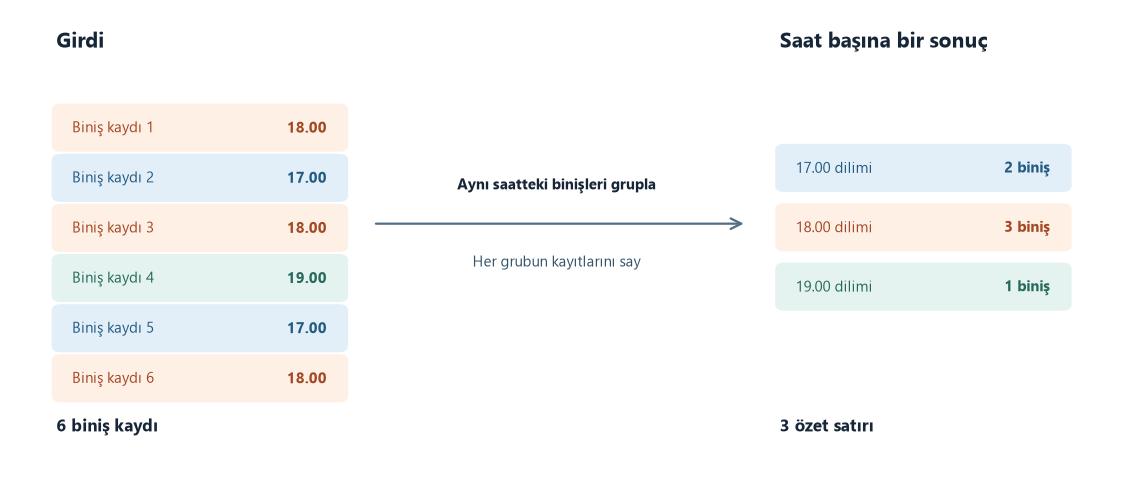

In [2]:
from matplotlib.patches import FancyBboxPatch

ornek_saatler = (18, 17, 18, 19, 17, 18)
ornek_gruplar = pd.DataFrame({"pickup_hour": ornek_saatler}).groupby("pickup_hour").size()
assert list(ornek_gruplar.items()) == [(17, 2), (18, 3), (19, 1)]
renkler = {17: ("#E3EFF8", "#245B83"), 18: ("#FFF0E6", "#A34824"),
           19: ("#E4F3EF", "#28695D")}

fig, ax = plt.subplots(figsize=(11.2, 4.7), layout="constrained")
ax.set(xlim=(0, 12), ylim=(0, 7))
ax.set_axis_off()
ax.text(0.5, 6.42, "Girdi", fontsize=15, weight="bold", color="#172637")
ax.text(8.31, 6.42, "Saat başına bir sonuç", fontsize=15, weight="bold", color="#172637")

def satir(x, y, hour_value, label, count):
    fill, ink = renkler[hour_value]
    ax.add_patch(FancyBboxPatch((x, y), 3.1, 0.63, boxstyle="round,pad=0.05,rounding_size=.1",
                                facecolor=fill, edgecolor="none"))
    ax.text(x + .17, y + .30, label, fontsize=11, color=ink, va="center")
    ax.text(x + 2.92, y + .30, count, fontsize=11, weight="bold", color=ink, ha="right", va="center")

for row, hour_value in enumerate(ornek_saatler, 1):
    satir(.5, 5.65 - .76 * row, hour_value, f"Biniş kaydı {row}", f"{hour_value:02d}.00")
for index, (hour_value, count) in enumerate(ornek_gruplar.items()):
    satir(8.31, 4.28 - .90 * index, hour_value, f"{hour_value:02d}.00 dilimi", f"{count} biniş")

ax.annotate("", xy=(7.95, 3.75), xytext=(3.92, 3.75),
            arrowprops={"arrowstyle": "->", "lw": 1.6, "color": "#536D82", "mutation_scale": 19})
ax.text(5.9, 4.27, "Aynı saatteki binişleri grupla", fontsize=11, weight="bold",
        ha="center", color="#172637")
ax.text(5.9, 3.10, "Her grubun kayıtlarını say", fontsize=11, ha="center", color="#36536A")
ax.text(.5, .60, "6 biniş kaydı", fontsize=12, weight="bold", color="#172637")
ax.text(8.31, .60, "3 özet satırı", fontsize=12, weight="bold", color="#172637")
show_figure(fig)


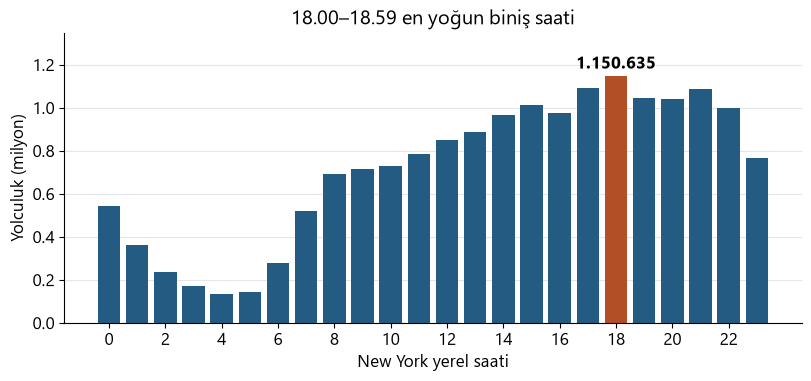

In [3]:
hourly = hour.sort_values("pickup_hour")
peak = hourly.loc[hourly.trip_count.idxmax()]
fig, ax = plt.subplots(figsize=(8, 3.7), layout="constrained")
colors = [ORANGE if value == peak.pickup_hour else BLUE for value in hourly.pickup_hour]
ax.bar(hourly.pickup_hour, hourly.trip_count / 1_000_000, color=colors)
ax.set(title=f"{int(peak.pickup_hour):02d}.00–{int(peak.pickup_hour):02d}.59 en yoğun biniş saati", xlabel="New York yerel saati",
       ylabel="Yolculuk (milyon)", ylim=(0, 1.35))
ax.set_xticks(range(0, 24, 2))
ax.grid(axis="y")
ax.annotate(tr_int(peak.trip_count), (peak.pickup_hour, peak.trip_count / 1_000_000),
            xytext=(0, 5), textcoords="offset points", ha="center", fontweight="bold")
show_figure(fig, "11_s3_hour.png")

### 18.00 nasıl öne çıkıyor?

Hafta içi günlerinin toplamında 21.00 az farkla önde. Hafta sonu 18.00’ın farkı daha büyük ve dönem toplamını öne geçiriyor. Grafikte her grubun biniş toplamı o grubun gün sayısına bölündü. Dönemde hafta içinden 107, hafta sonundan 44 gün var.

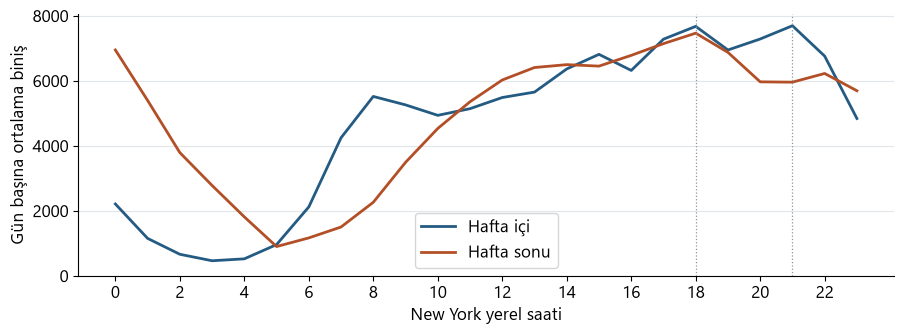

,18.00 toplamı,21.00 toplamı,18.00 ile 21.00 farkı
Dönem,,,
Hafta içi,821.861,823.992,-2.131
Hafta sonu,328.774,262.452,66.322


In [4]:
pattern = spark_tables["pattern"].copy()
pattern["weekday"] = (pattern["pickup_dow"] + 5) % 7
weekdays = ["Pazartesi", "Salı", "Çarşamba", "Perşembe", "Cuma", "Cumartesi", "Pazar"]
days_per_weekday = day["pickup_date"].dt.dayofweek.value_counts()

by_day_type = {}
for label, indices in (("Hafta içi", range(5)), ("Hafta sonu", (5, 6))):
    subset = pattern.loc[pattern["weekday"].isin(indices)]
    by_day_type[label] = (subset.groupby("pickup_hour")["trip_count"].sum()
                          / days_per_weekday.reindex(indices).sum())
type_profile = pd.DataFrame(by_day_type)
ax = type_profile.plot(figsize=(9.2, 3.5), color=[BLUE, ORANGE], linewidth=2)
ax.set(xlabel="New York yerel saati", ylabel="Gün başına ortalama biniş", ylim=(0, None))
ax.set_xticks(range(0, 24, 2))
for hour_mark in (18, 21):
    ax.axvline(hour_mark, color="#8797A3", linewidth=0.9, linestyle=":")
ax.grid(axis="y")
plt.tight_layout()
plt.show()

comparison = []
for label, indices in (("Hafta içi", range(5)), ("Hafta sonu", (5, 6))):
    two = (pattern.loc[pattern["weekday"].isin(indices) & pattern["pickup_hour"].isin([18, 21])]
           .groupby("pickup_hour")["trip_count"].sum())
    comparison.append([label, tr_int(two[18]), tr_int(two[21]), tr_int(two[18] - two[21])])
display(pd.DataFrame(comparison, columns=["Dönem", "18.00 toplamı", "21.00 toplamı", "18.00 ile 21.00 farkı"])
        .set_index("Dönem"))


Hafta içi 21.00 **2.131** biniş önde. Hafta sonu 18.00’ın **66.322** binişlik üstünlüğü bu farkı kapatıyor. Bu, genel zirvenin nasıl oluştuğunu gösterir. Yolculuk amacı TLC kaydında bulunmadığından iş çıkışının veya turizmin katkısını ölçemiyoruz.

### Hafta günü ve saat birlikte

Her hücre belirli bir hafta gününün o saatteki ortalama binişidir. Sütunun tamamını birleştirerek bulunan hafta içi ortalaması ayrı bir ölçüdür.

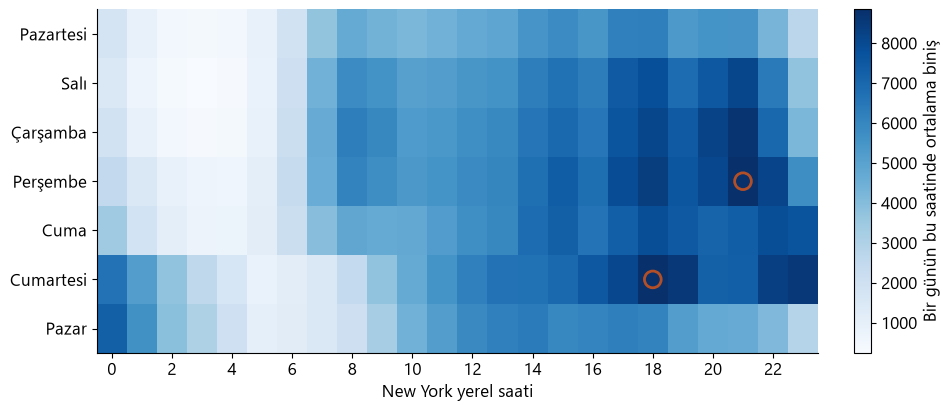

,Hafta günü,Saat aralığı,Ortalamaya giren gün,Ortalama biniş
Dönem,,,,
Hafta içi,Perşembe,21.00–21.59,22,8.830
Hafta sonu,Cumartesi,18.00–18.59,22,8.853


In [5]:
pattern["mean_trips"] = pattern["trip_count"] / pattern["weekday"].map(days_per_weekday)
matrix = pattern.pivot(index="weekday", columns="pickup_hour", values="mean_trips")
fig, ax = plt.subplots(figsize=(9.4, 4.0), layout="constrained")
image = ax.imshow(matrix, aspect="auto", cmap="Blues")
ax.set(xlabel="New York yerel saati")
ax.set_xticks(range(0, 24, 2))
ax.set_yticks(range(7), weekdays)
peak_cells = []
for period, subset in (("Hafta içi", matrix.iloc[:5]), ("Hafta sonu", matrix.iloc[5:])):
    weekday, hour_index = subset.stack().idxmax()
    ax.scatter(hour_index, weekday, s=145, facecolors="none", edgecolors=ORANGE, linewidths=2)
    peak_cells.append({
        "Dönem": period,
        "Hafta günü": weekdays[weekday],
        "Saat aralığı": f"{hour_index:02d}.00–{hour_index:02d}.59",
        "Ortalamaya giren gün": int(days_per_weekday[weekday]),
        "Ortalama biniş": tr_int(matrix.loc[weekday, hour_index]),
    })
fig.colorbar(image, ax=ax, label="Bir günün bu saatinde ortalama biniş")
show_figure(fig)

display(pd.DataFrame(peak_cells).set_index("Dönem"))


Tablo, işaretli iki hücreyi ısı haritasını üreten değerlerden alır. Her ortalama, ilgili hafta gününün dönem boyunca o saat dilimindeki binişlerini gösterir.

In [6]:
sorgulari_goster(
    [spark_queries.hourly_trip_counts, spark_queries.weekday_hour_trip_counts],
    [kiyas.pandas_hourly, kiyas.pandas_weekday_hour],
)

**PySpark**

```python
def hourly_trip_counts(trips: DataFrame) -> DataFrame:
    """Count pickups by New York local hour, busiest first."""
    return (
        trips.groupBy("pickup_hour")
        .count()
        .withColumnRenamed("count", "trip_count")
        .orderBy(F.desc("trip_count"), F.asc("pickup_hour"))
    )

def weekday_hour_trip_counts(trips: DataFrame) -> DataFrame:
    """Count pickups by Spark weekday (Sunday=1) and New York local hour."""
    return (
        trips.groupBy("pickup_dow", "pickup_hour")
        .count()
        .withColumnRenamed("count", "trip_count")
        .orderBy("pickup_dow", "pickup_hour")
    )
```

**pandas**

```python
def pandas_hourly(trips):
    return (trips.groupby("pickup_hour", dropna=False).size().reset_index(name="trip_count")
            .sort_values(["trip_count", "pickup_hour"], ascending=[False, True]))

def pandas_weekday_hour(trips):
    return (trips.groupby(["pickup_dow", "pickup_hour"], dropna=False, sort=True)
            .size().reset_index(name="trip_count"))
```

## Gün

**25 Nisan 2026, 153.232 binişle dönemin en yoğun günü.** 18 Nisan’a göre artış **%8,4**. Son yedi günün hareketli ortalaması **123.804** biniş.

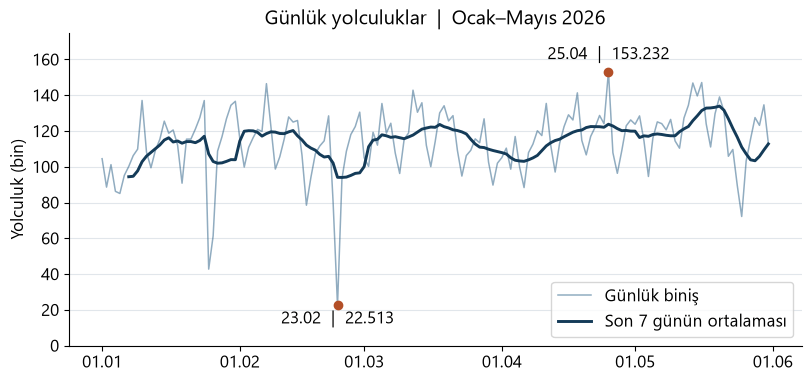

In [7]:
peak_day = day.loc[day.trip_count.idxmax()]
low_day = day.loc[day.trip_count.idxmin()]
fig, ax = plt.subplots(figsize=(8, 3.7), layout="constrained")
ax.plot(day.pickup_date, day.trip_count / 1_000, color=BLUE, alpha=0.5, linewidth=1.1, label="Günlük biniş")
ax.plot(day.pickup_date, day.trailing_7d_avg / 1_000, color="#143b58",
        linewidth=2.1, label="Son 7 günün ortalaması")
ax.legend(loc="lower right")
for row, offset in ((peak_day, 9), (low_day, -13)):
    pos = row.pickup_date, row.trip_count / 1_000
    ax.scatter(*pos, color=ORANGE, zorder=3)
    ax.annotate(f"{row.pickup_date:%d.%m}  |  {tr_int(row.trip_count)}", pos,
                xytext=(0, offset), textcoords="offset points", ha="center")
ax.set(title="Günlük yolculuklar  |  Ocak–Mayıs 2026", ylabel="Yolculuk (bin)", ylim=(0, 175))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
ax.grid(axis="y")
show_figure(fig, "12_s3_day.png")

**23 Şubat dönemin en düşük günü.** Aşağıdaki tablo diğer pazartesilerle farkını gösterir. 22–23 Şubat kar fırtınasında Central Park’ta yaklaşık 50 cm kar ölçüldü ve araç trafiği kısıtlaması 23 Şubat öğlene kadar yürürlükte kaldı. Bunlar düşüşün yaşandığı günün belgelenmiş koşullarıdır. Yolculuk kayıtları, karın ve trafik kısıtlamasının ayrı etkilerini ölçmeye elverişli değildir. [NWS kar raporu](https://www.weather.gov/okx/20260222_23), [New York Belediyesi kararı](https://www.nyc.gov/mayors-office/news/2026/02/emergency-executive-order-no--3)

In [8]:
low_date = pd.Timestamp("2026-02-23")
mondays = day.loc[day["pickup_date"].dt.dayofweek.eq(0)].set_index("pickup_date")["trip_count"]
other_mondays = mondays.drop(index=low_date)
display(pd.DataFrame({
    "Karşılaştırma": ["23 Şubat", "Diğer pazartesiler"],
    "Gün sayısı": [1, len(other_mondays)],
    "Günlük ortalama biniş": [tr_int(mondays.loc[low_date]), tr_int(other_mondays.mean())],
}).set_index("Karşılaştırma"))


,Gün sayısı,Günlük ortalama biniş
Karşılaştırma,,
23 Şubat,1,22.513
Diğer pazartesiler,20,93.592


### 25 Nisan’daki artış ne zaman ve nerede oldu?

Aşağıdaki saat ve bölge sayımları iki yöntemle de temiz veriden üretildi. 25 Nisan’ı Ocak–Mayıs dönemindeki **diğer 21 cumartesinin ortalamasıyla** karşılaştırdık.

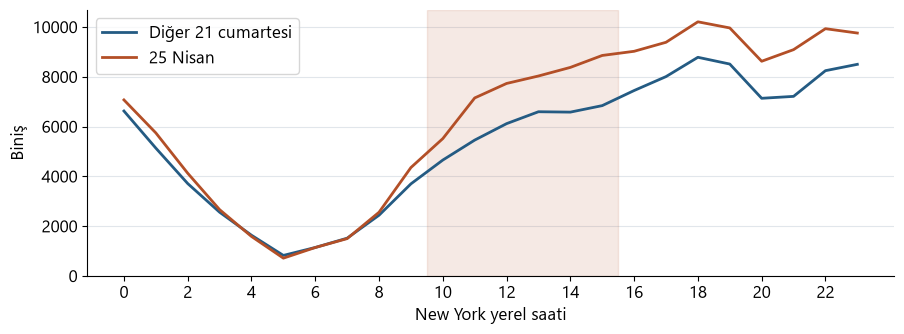

,Süre (saat),Diğer cumartesiler,25 Nisan,Ek biniş,Saat başına ek biniş
Saat,,,,,
00.00–09.59,10,29.343,31.514,2.171,217
10.00–15.59,6,36.279,45.695,9.416,1.569
16.00–23.59,8,63.885,76.023,12.138,1.517


,Diğer cumartesiler,25 Nisan,Fark
"Biniş bölgesi, 10.00–15.59",,,
Diğer Manhattan,24.269,31.707,7.438
Upper East Side North,1.821,2.712,891
Upper East Side South,1.971,2.805,834
Diğer bölgeler,1.744,2.364,620
JFK ve LaGuardia,1.718,1.902,184
Broadway çevresi (6 bölge),4.757,4.205,-552


In [9]:
by_date_hour = (saturdays.groupby(["pickup_date", "pickup_hour"])["trip_count"]
                .sum().unstack(fill_value=0))
peak_date = pd.Timestamp("2026-04-25")
ordinary = by_date_hour.drop(index=peak_date).mean()
peak_counts = by_date_hour.loc[peak_date]
assert peak_counts.sum() == 153_232 and len(by_date_hour) == 22
peak_profile = pd.DataFrame({"Diğer 21 cumartesi": ordinary, "25 Nisan": peak_counts})
ax = peak_profile.plot(figsize=(9.2, 3.5), color=[BLUE, ORANGE], linewidth=2)
ax.axvspan(9.5, 15.5, alpha=0.12, color=ORANGE)
ax.set(xlabel="New York yerel saati", ylabel="Biniş", ylim=(0, None))
ax.set_xticks(range(0, 24, 2))
ax.grid(axis="y")
plt.tight_layout()
plt.show()

periods = [("00.00–09.59", range(10)), ("10.00–15.59", range(10, 16)), ("16.00–23.59", range(16, 24))]
period_table = []
for label, hours in periods:
    actual = peak_counts.loc[list(hours)].sum()
    expected = ordinary.loc[list(hours)].sum()
    extra = actual - expected
    period_table.append([label, len(hours), tr_int(expected), tr_int(actual),
                         tr_int(extra), tr_int(extra / len(hours))])
display(pd.DataFrame(period_table, columns=[
    "Saat", "Süre (saat)", "Diğer cumartesiler", "25 Nisan", "Ek biniş",
    "Saat başına ek biniş",
]).set_index("Saat"))

event_hours = saturdays.loc[saturdays["pickup_hour"].between(10, 15)]
area_count = event_hours.groupby(["area", event_hours["pickup_date"].eq(peak_date)])["trip_count"].sum().unstack(fill_value=0)
area_count[False] = area_count[False] / 21
area_count["Fark"] = area_count[True] - area_count[False]
area_count = area_count.sort_values("Fark", ascending=False).rename(columns={False: "Diğer cumartesiler", True: "25 Nisan"})
display(area_count.map(tr_int).rename_axis(index="Biniş bölgesi, 10.00–15.59", columns=None))


<a id="pik-gun-kontrolu"></a>

#### 25 Nisan farklı karşılaştırmalarda da zirve mi?

Bir önceki hafta alışılmadık olabilir. Bu yüzden haftanın aynı gününü koruyarak üç dayanak kullandık. Ortanca, karşılaştırma grubundaki aşırı yüksek ve düşük günlerden ortalamaya göre daha az etkilenir.

In [10]:
saturday_totals = by_date_hour.sum(axis=1)
peak_total = saturday_totals.loc[peak_date]
other_saturdays = saturday_totals.drop(peak_date)
assert len(other_saturdays) == 21 and peak_total > other_saturdays.max()

baselines = pd.Series({
    "Önceki cumartesi (18 Nisan)": saturday_totals.loc[peak_date - pd.Timedelta(days=7)],
    "En yakın 4 cumartesi (iki önce, iki sonra)": saturday_totals.reindex(
        peak_date + pd.to_timedelta([-14, -7, 7, 14], unit="D")
    ).mean(skipna=False),
    "Diğer 21 cumartesinin ortancası": other_saturdays.median(),
}, name="Karşılaştırma binişi")
assert baselines.notna().all()

comparison = baselines.to_frame()
comparison["Ek biniş"] = peak_total - baselines
comparison["Artış"] = (100 * (peak_total / baselines - 1)).map(lambda v: f"+%{tr_dec(v, 1)}")
for column in ("Karşılaştırma binişi", "Ek biniş"):
    comparison[column] = comparison[column].map(tr_int)
display(comparison.rename_axis("25 Nisan ile karşılaştırılan"))
display(Markdown(
    f"**25 Nisan, 22 cumartesi arasında 1. sırada.** "
    f"Üç karşılaştırmada da {tr_int(peak_total)} biniş en yüksek. "
    "Bu kontrol artışın karşılaştırma seçimine bağlı olmadığını gösterir. "
    "Yolculuk kayıtlarında yolcunun seçim nedeni yer almadığı için etkinlik veya yağışın payı ölçülemez. "
    "[TLC veri sözlüğü](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)"
))

,Karşılaştırma binişi,Ek biniş,Artış
25 Nisan ile karşılaştırılan,,,
Önceki cumartesi (18 Nisan),141.356,11.876,"+%8,4"
"En yakın 4 cumartesi (iki önce, iki sonra)",132.934,20.298,"+%15,3"
Diğer 21 cumartesinin ortancası,128.600,24.632,"+%19,2"


**25 Nisan, 22 cumartesi arasında 1. sırada.** Üç karşılaştırmada da 153.232 biniş en yüksek. Bu kontrol artışın karşılaştırma seçimine bağlı olmadığını gösterir. Yolculuk kayıtlarında yolcunun seçim nedeni yer almadığı için etkinlik veya yağışın payı ölçülemez. [TLC veri sözlüğü](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)

25 Nisan’da 10.00–16.00 arasında **Car-Free Earth Day** düzenlendi. Bu saatlerde Manhattan’da yaklaşık **8.612** ek biniş vardı. Broadway çevresinden seçilen altı TLC bölgesinde ortalama **4.757** olan sayım **4.205** oldu. Upper East Side North ve South bölgelerinde sırasıyla yaklaşık **891** ve **834** ek biniş görüldü. Şehir genelinde toplam ek biniş **16.00’dan sonra** daha fazlaydı. Saat başına ek biniş ise **10.00–15.59** aralığında biraz daha yüksekti.

Central Park’ta 16.00’ya kadar **8,4 mm**, gün sonunda **34,5 mm** yağış ölçüldü. Etkinlik ve yağış aynı günün bağlamıdır. Altı TLC bölgesi kapanan sokakların tam sınırı değildir. Veriden bu etkenlerin ayrı katkıları hesaplanamaz. [NYC DOT etkinlik güzergâhları](https://www.nyc.gov/html/dot/html/pedestrians/earthday.shtml), [NWS saat 16.00 raporu](https://mesonet.agron.iastate.edu/wx/afos/p.php?e=202604252034&pil=CLINYC), [NOAA günlük ölçümü](https://www.ncei.noaa.gov/access/services/data/v1?dataset=daily-summaries&endDate=2026-04-30&format=pdf&startDate=2026-04-01&stations=USW00094728)

### Window hangi bilgiyi ekliyor?

Pencere günlük tablonun **151 tarihini korur**. `rowsBetween(-6, 0)` bugünü ve önceki altı satırı kapsar. Ortalama ilk altı günde boştur, **7 Ocak** ilk tam penceredir. `lag(7)` için ilk yedi gün boştur, **8 Ocak** ilk karşılaştırma günüdür. Tarihler kesintisiz olduğu için yedi satır önce, yedi gün öncedir.

24 Nisan satırında pencere **18–24 Nisan** arasını kapsar. Ertesi satıra geçince **18 Nisan çıkar ve 25 Nisan girer**. Kesikli ok, `lag(7)` ile yedi gün önceki biniş sayısının hangi satıra eklendiğini gösterir.

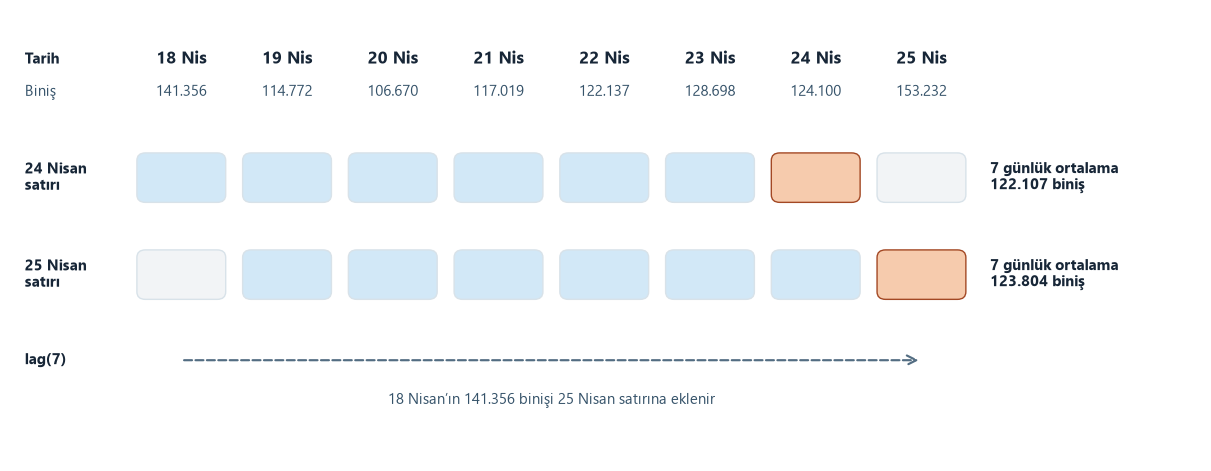

Renkli kutular ortalamaya giren günleri, turuncu kutu hesabın yazıldığı günü gösterir. 25 Nisan için **866.628 ÷ 7 = 123.804 biniş**.

In [11]:
from matplotlib.patches import FancyBboxPatch

april = day.loc[day["pickup_date"].between("2026-04-18", "2026-04-25")].reset_index(drop=True)
assert len(april) == 8
last = april.iloc[-1]
assert last["previous_week_trips"] == april.iloc[0]["trip_count"]
assert last["trailing_7d_avg"] == april.iloc[1:]["trip_count"].mean()

fig, ax = plt.subplots(figsize=(12.0, 4.6), layout="constrained")
ax.set(xlim=(-1.62, 9.65), ylim=(0, 4.75))
ax.set_axis_off()
for i, row in enumerate(april.itertuples()):
    ax.text(i, 4.18, f"{row.pickup_date.day} Nis", ha="center", color="#172637",
            fontsize=12, weight="bold")
    ax.text(i, 3.84, tr_int(row.trip_count), ha="center", color="#36536A", fontsize=10.5)
ax.text(-1.48, 4.18, "Tarih", fontsize=11, color="#172637", weight="bold")
ax.text(-1.48, 3.84, "Biniş", fontsize=11, color="#36536A")

for stop, y in ((6, 2.98), (7, 1.96)):
    current = april.iloc[stop]
    ax.text(-1.48, y, f"{current['pickup_date'].day} Nisan\nsatırı", va="center",
            fontsize=11, weight="bold", color="#172637")
    for i in range(len(april)):
        included = stop - 6 <= i <= stop
        fill = "#F6CBAD" if i == stop else "#D2E8F7" if included else "#F2F4F6"
        edge = "#A34824" if i == stop else "#D8E2E9"
        ax.add_patch(FancyBboxPatch((i - .39, y - .23), .78, .46,
                                    boxstyle="round,pad=.03,rounding_size=.08",
                                    facecolor=fill, edgecolor=edge, linewidth=1))
    ax.text(7.65, y, f"7 günlük ortalama\n{tr_int(current['trailing_7d_avg'])} biniş",
            va="center", fontsize=10.7, weight="bold", color="#172637")

ax.text(-1.48, 1.06, "lag(7)", color="#172637", fontsize=11, weight="bold", va="center")
ax.annotate("", xy=(7, 1.06), xytext=(0, 1.06),
            arrowprops={"arrowstyle": "->", "linestyle": "--", "lw": 1.55,
                        "color": "#536D82", "mutation_scale": 17})
ax.text(3.5, .60, f"18 Nisan’ın {tr_int(last['previous_week_trips'])} binişi 25 Nisan satırına eklenir",
        ha="center", fontsize=11, color="#36536A")
show_figure(fig)
display(Markdown(
    f"Renkli kutular ortalamaya giren günleri, turuncu kutu hesabın yazıldığı günü gösterir. "
    f"25 Nisan için **{tr_int(april.iloc[1:]['trip_count'].sum())} ÷ 7 = "
    f"{tr_int(last['trailing_7d_avg'])} biniş**."
))


In [12]:
def gun_tablosu(frame):
    return pd.DataFrame({
        "Tarih": frame["pickup_date"].dt.strftime("%d.%m.%Y"),
        "Biniş": frame["trip_count"].map(tr_int),
        "7 gün önce": frame["previous_week_trips"].map(lambda x: "—" if pd.isna(x) else tr_int(x)),
        "Son 7 günün ort.": frame["trailing_7d_avg"].map(lambda x: "—" if pd.isna(x) else tr_int(x)),
        "Haftalık değişim": frame["week_change_pct"].map(lambda x: "—" if pd.isna(x) else ("−" if x < 0 else "") + "%" + tr_dec(abs(x), 1)),
    }).set_index("Tarih")

display(gun_tablosu(day.head(8)))
display(gun_tablosu(day.loc[day["pickup_date"].between("2026-04-18", "2026-04-25")]))


,Biniş,7 gün önce,Son 7 günün ort.,Haftalık değişim
Tarih,,,,
01.01.2026,104.527,—,—,—
02.01.2026,88.641,—,—,—
03.01.2026,101.197,—,—,—
04.01.2026,86.266,—,—,—
05.01.2026,85.088,—,—,—
06.01.2026,95.187,—,—,—
07.01.2026,100.191,—,94.442,—
08.01.2026,106.233,104.527,94.686,"%1,6"


,Biniş,7 gün önce,Son 7 günün ort.,Haftalık değişim
Tarih,,,,
18.04.2026,141.356,135.435,120.181,"%4,4"
19.04.2026,114.772,112.074,120.566,"%2,4"
20.04.2026,106.670,97.077,121.937,"%9,9"
21.04.2026,117.019,113.052,122.504,"%3,5"
22.04.2026,122.137,122.444,122.460,"−%0,3"
23.04.2026,128.698,129.069,122.407,"−%0,3"
24.04.2026,124.100,126.195,122.107,"−%1,7"
25.04.2026,153.232,141.356,123.804,"%8,4"


In [13]:
sorgulari_goster(
    [spark_queries.daily_trip_counts, spark_queries.daily_window_metrics],
    [kiyas.pandas_daily],
)

**PySpark**

```python
def daily_trip_counts(trips: DataFrame) -> DataFrame:
    """Count pickups per New York calendar date, earliest first."""
    return (
        trips.withColumn("pickup_date", F.to_date("tpep_pickup_datetime"))
        .groupBy("pickup_date")
        .count()
        .withColumnRenamed("count", "trip_count")
        .orderBy("pickup_date")
    )

def daily_window_metrics(daily: DataFrame) -> DataFrame:
    """Compare calendar days and compute a full trailing seven-day average."""
    ordered = Window.orderBy("pickup_date")
    trailing = ordered.rowsBetween(-6, 0)
    return (
        daily.withColumn("previous_week_trips", F.lag("trip_count", 7).over(ordered))
        .withColumn("trailing_7d_avg", F.when(F.count("trip_count").over(trailing) == 7,
                                               F.avg("trip_count").over(trailing)))
        .withColumn("week_change_pct", F.when(F.col("previous_week_trips") > 0,
                    100.0 * (F.col("trip_count") - F.col("previous_week_trips")) / F.col("previous_week_trips")))
        .orderBy("pickup_date")
    )
```

**pandas**

```python
def pandas_daily(trips):
    pickup_date = trips["tpep_pickup_datetime"].dt.normalize().rename("pickup_date")
    daily = trips.groupby(pickup_date, dropna=False).size().reset_index(name="trip_count")
    daily = daily.sort_values("pickup_date")
    counts = daily["trip_count"]
    previous = counts.shift(7)
    return daily.assign(
        previous_week_trips=previous,
        trailing_7d_avg=counts.rolling(7, min_periods=7).mean(),
        week_change_pct=100 * (counts - previous) / previous.where(previous.gt(0)),
    )
```

## Bölge

**237 numaralı Upper East Side South**, **815.297** binişle ilk sırada. Bu bölge Central Park’ın doğusundaki Yukarı Doğu Yakası’nın güney kesimidir.

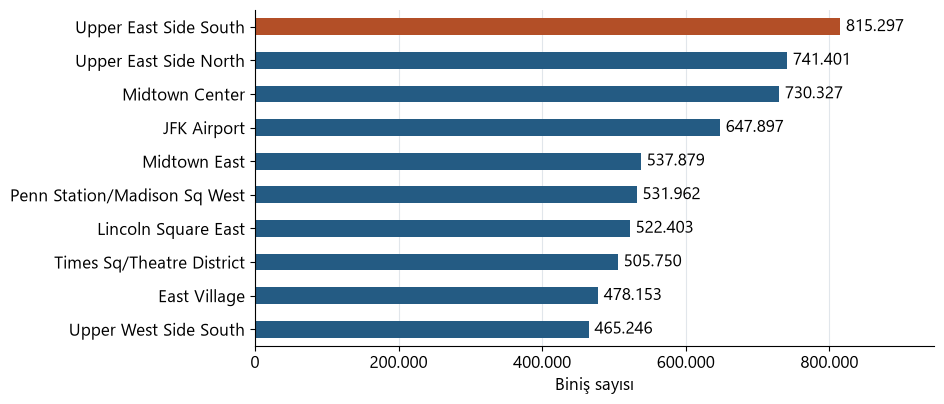

,Resmî TLC adı,İlçe,Türkçe konum,Biniş
TLC kodu,,,,
237,Upper East Side South,Manhattan,Yukarı Doğu Yakası’nın güney kesimi,815.297
236,Upper East Side North,Manhattan,Yukarı Doğu Yakası’nın kuzey kesimi,741.401
161,Midtown Center,Manhattan,Midtown’ın merkez kesimi,730.327
132,JFK Airport,Queens,John F. Kennedy Havalimanı,647.897
162,Midtown East,Manhattan,Midtown’ın doğu kesimi,537.879
186,Penn Station/Madison Sq West,Manhattan,Penn İstasyonu ve Madison Square Garden çevresi,531.962
142,Lincoln Square East,Manhattan,Lincoln Meydanı’nın doğusu,522.403
230,Times Sq/Theatre District,Manhattan,Times Meydanı ve Tiyatro Bölgesi,505.750
79,East Village,Manhattan,Manhattan’ın doğusunda East Village,478.153


In [14]:
konum = {
    237: "Yukarı Doğu Yakası’nın güney kesimi", 236: "Yukarı Doğu Yakası’nın kuzey kesimi",
    161: "Midtown’ın merkez kesimi", 132: "John F. Kennedy Havalimanı",
    162: "Midtown’ın doğu kesimi", 186: "Penn İstasyonu ve Madison Square Garden çevresi",
    142: "Lincoln Meydanı’nın doğusu", 230: "Times Meydanı ve Tiyatro Bölgesi",
    79: "Manhattan’ın doğusunda East Village", 239: "Yukarı Batı Yakası’nın güney kesimi",
    138: "LaGuardia Havalimanı", 7: "Queens’in kuzeybatısında Astoria",
    70: "Queens’te LaGuardia’nın güneyindeki East Elmhurst",
}
top = zone.head(10).copy()
top["Türkçe konum"] = top["PULocationID"].map(konum)
axes = top.iloc[::-1].plot.barh(x="pickup_zone", y="trip_count", figsize=(9.6, 4.2),
                              color=[BLUE] * 9 + [ORANGE], legend=False)
axes.set(xlabel="Biniş sayısı", ylabel="")
axes.xaxis.set_major_formatter(lambda v, p: tr_int(v))
axes.set_xlim(0, top["trip_count"].max() * 1.16)
axes.bar_label(axes.containers[0], labels=top["trip_count"].iloc[::-1].map(tr_int), padding=4)
axes.grid(axis="x")
plt.tight_layout()
plt.show()
display(top.assign(trip_count=top["trip_count"].map(tr_int)).rename(columns={
    "PULocationID": "TLC kodu", "pickup_zone": "Resmî TLC adı",
    "borough": "İlçe", "trip_count": "Biniş",
}).set_index("TLC kodu")[["Resmî TLC adı", "İlçe", "Türkçe konum", "Biniş"]])


### Harita ve kapsam

Harita **17.210.743** binişi kapsıyor. Kullanılan GeoJSON dosyasında **57 (Corona)** ve **105 (Governor’s, Ellis ve Liberty adaları)** kodlarına karşılık gelen geometri bulunmadı. Bu kodlardaki **212 + 6 = 218** biniş harita dışında kaldı. **17.210.961** binişlik genel toplam bu kayıtları içeriyor. [NYC Taxi Zones sınırları](https://catalog.data.gov/dataset/nyc-taxi-zones)

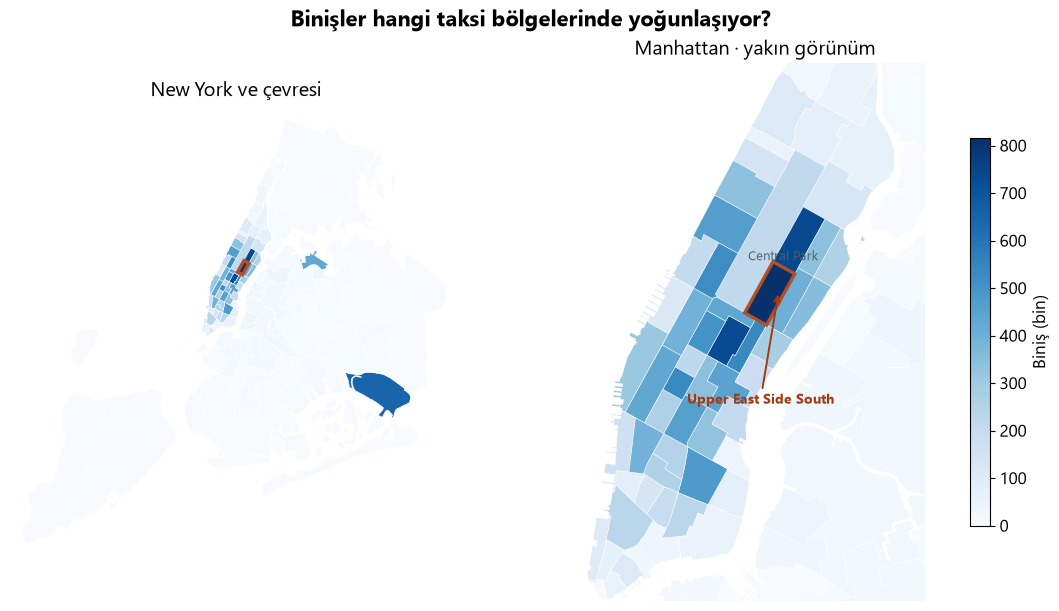

Haritada gösterilen: 17.210.743 / 17.210.961 yolculuk


,Haritada eşleşmeyen bölge,Biniş
TLC kodu,,
57,Corona,212
105,Governor's Island/Ellis Island/Liberty Island,6


In [15]:
import json
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize
from matplotlib.patches import Polygon
from IPython.display import Image, display

geometry_file = root / "data" / "raw" / "taxi_zones.geojson"
map_name = "16_s3_pickup_map.png"

if geometry_file.exists():
    shapes = json.loads(geometry_file.read_text(encoding="utf-8"))["features"]
    counts = zone.set_index("PULocationID").trip_count
    peak_id = int(counts.idxmax())
    norm = Normalize(0, counts.max() / 1_000)
    shapes_by_id = {}
    for feature in shapes:
        zone_id = int(feature["properties"]["locationid"])
        geometry = feature["geometry"]
        polygons = geometry["coordinates"]
        if geometry["type"] == "Polygon":
            polygons = [polygons]
        shapes_by_id.setdefault(zone_id, []).extend(polygon[0] for polygon in polygons)

    assert peak_id in shapes_by_id
    mapped = int(counts.reindex(shapes_by_id, fill_value=0).sum())
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 6), layout="constrained")
    for ax in axes:
        patches, values = [], []
        for zone_id, outlines in shapes_by_id.items():
            for outline in outlines:
                patches.append(Polygon(outline, closed=True))
                values.append(counts.get(zone_id, 0) / 1_000)
        collection = PatchCollection(patches, cmap="Blues", norm=norm,
                                     edgecolor="#ffffff", linewidth=0.35)
        collection.set_array(values)
        ax.add_collection(collection)
        for outline in shapes_by_id[peak_id]:
            ax.add_patch(Polygon(outline, closed=True, fill=False, edgecolor=ORANGE, linewidth=2.4))
        ax.set_aspect(1.32)
        ax.set_axis_off()

    axes[0].set(title="New York ve çevresi", xlim=(-74.27, -73.68), ylim=(40.48, 40.93))
    axes[1].set(title="Manhattan · yakın görünüm", xlim=(-74.02, -73.92), ylim=(40.70, 40.82))
    axes[1].annotate("Central Park", (-73.972, 40.776), color="#515f69", fontsize=9)
    axes[1].annotate("Upper East Side South", xy=(-73.963, 40.769), xytext=(-73.990, 40.744),
                     arrowprops={"arrowstyle": "->", "color": "#a33a11", "lw": 1.4},
                     color="#a33a11", fontsize=10, fontweight="bold")
    fig.suptitle("Binişler hangi taksi bölgelerinde yoğunlaşıyor?", fontsize=16, fontweight="bold")
    fig.colorbar(collection, ax=axes, shrink=0.72, label="Biniş (bin)")
    show_figure(fig, map_name)
    print(f"Haritada gösterilen: {tr_int(mapped)} / {tr_int(counts.sum())} yolculuk")
    missing = zone.loc[~zone["PULocationID"].isin(shapes_by_id)]
    assert mapped + missing["trip_count"].sum() == counts.sum()
    display(missing[["PULocationID", "pickup_zone", "trip_count"]].rename(columns={
        "PULocationID": "TLC kodu", "pickup_zone": "Haritada eşleşmeyen bölge",
        "trip_count": "Biniş",
    }).set_index("TLC kodu"))
else:
    display(Image(filename=str(figures / map_name)))


### Queens’te %80 eşiğine nasıl ulaşıldı?

`partitionBy("borough")` her ilçeyi ayrı alır. Spark, bölgeleri biniş sırasına koyup biriken sayıyı hesaplar. Pandas aynı işlemi grup içinde `cumcount` ve `cumsum` ile yapar.

**Bu pencere ilk bölgeden başlar ve her satırda bir bölge büyür.** Önceki grafikteki yedi günlük pencere ise her adımda yedi gün kalır. Aşağıdaki tabloda ilk üç bölge %78,42’de kalır ve dördüncü bölge eklenince pay %80,88’e çıkar.

`5 × biriken biniş ≥ 4 × ilçe toplamı` kontrolü, en az %80 şartını bölme yapmadan sınar. Böylece karar, gösterimdeki yüzde yuvarlamasından etkilenmez.

In [16]:
queen_zones = zone.loc[zone["borough"].eq("Queens")]
top4 = queen_zones.head(4)
steps = top4.assign(biriken_binis=top4["trip_count"].cumsum()).iloc[1:].copy()
steps["Birikimli biniş payı"] = steps["biriken_binis"].div(queen_zones["trip_count"].sum()).mul(100).map(lambda x: "%" + tr_dec(x))
steps["Kapsanan bölge"] = [f"{n}/{len(queen_zones)}" for n in (2, 3, 4)]
names = top4["pickup_zone"].tolist()
steps["Eklenen bölge"] = [" ve ".join(names[:2]), *names[2:]]
steps["Biriken biniş"] = steps["biriken_binis"].map(tr_int)
display(steps[["Eklenen bölge", "Biriken biniş", "Birikimli biniş payı", "Kapsanan bölge"]].set_index("Eklenen bölge"))

concentration = spark_tables["zone_concentration"]
display(concentration.assign(
    borough_total=concentration["borough_total"].map(tr_int),
    cumulative_pct=concentration["cumulative_pct"].map(lambda x: "%" + tr_dec(x)),
    observed_zones_pct=concentration["observed_zones_pct"].map(lambda x: "%" + tr_dec(x)),
)[["borough", "borough_total", "zones_to_80pct", "observed_zones", "observed_zones_pct",
   "cumulative_pct"]].rename(columns={
    "borough": "İlçe", "borough_total": "İlçe binişi", "zones_to_80pct": "%80 için bölge",
    "observed_zones": "Biniş kaydı olan bölge", "observed_zones_pct": "Kapsanan bölge oranı",
    "cumulative_pct": "Birikimli biniş payı",
}).set_index("İlçe"))
outside = zone.loc[~zone["borough"].isin(kiyas.BOROUGHS), ["pickup_zone", "trip_count"]]
assert concentration["borough_total"].sum() + outside["trip_count"].sum() == zone["trip_count"].sum()
display(outside.rename(columns={"pickup_zone": "Beş NYC ilçesi dışındaki bölge",
                                "trip_count": "Biniş"}).set_index("Beş NYC ilçesi dışındaki bölge"))


,Biriken biniş,Birikimli biniş payı,Kapsanan bölge
Eklenen bölge,,,
JFK Airport ve LaGuardia Airport,1.083.894,"%75,82",2/69
Astoria,1.120.952,"%78,42",3/69
East Elmhurst,1.156.215,"%80,88",4/69


,İlçe binişi,%80 için bölge,Biniş kaydı olan bölge,Kapsanan bölge oranı,Birikimli biniş payı
İlçe,,,,,
Queens,1.429.497,4,69,"%5,80","%80,88"
Brooklyn,490.455,23,61,"%37,70","%80,56"
Staten Island,1.576,8,19,"%42,11","%84,58"
Manhattan,15.212.024,30,67,"%44,78","%81,06"
Bronx,77.332,24,43,"%55,81","%81,09"


,Biniş
Beş NYC ilçesi dışındaki bölge,
Newark Airport,77


Queens’te dört bölge, binişlerin **%80,88’ini** kapsıyor. Bu dört bölge, biniş kaydı olan **69 bölgenin %5,8’i**. İlçe eşiği beş NYC ilçesi içinde hesaplanır. Staten Island satırının dayanağı **1.576** temiz biniştir.

**Bölge kodu nasıl ada dönüşüyor?**

| Biniş sayımındaki satır | 265 satırlık bölge sözlüğündeki eşleşme | Birleştirme sonrası |
| --- | --- | --- |
| 237 → 815.297 biniş | 237 → Upper East Side South, Manhattan | Upper East Side South, Manhattan → 815.297 biniş |

Spark `broadcast` ile küçük bölge sözlüğünü eşleştirmeyi yapan görevlere erişilebilir kılar. Sol birleştirme, sözlükte eşleşmesi bulunmayan sayım satırlarını da korur. pandas aynı eşleştirmeyi `merge(how="left")` ile yapar.

In [17]:
sorgulari_goster(
    [spark_queries.zone_trip_counts, spark_queries.zone_concentration],
    [kiyas.pandas_zones, kiyas.pandas_concentration],
)

**PySpark**

```python
def zone_trip_counts(trips: DataFrame, zones: DataFrame) -> DataFrame:
    """Count pickups by zone ID and attach the TLC zone and borough names."""
    lookup = zones.select(
        F.col("LocationID").cast("int").alias("PULocationID"),
        F.col("Borough").alias("borough"),
        F.col("Zone").alias("pickup_zone"),
    )
    counts = trips.groupBy("PULocationID").count().withColumnRenamed("count", "trip_count")
    return counts.join(F.broadcast(lookup), "PULocationID", "left").orderBy(
        F.desc("trip_count"), F.asc("PULocationID")
    )

def zone_concentration(zones: DataFrame) -> DataFrame:
    """Rank recorded zones and find the first prefix containing at least 80%."""
    districts = ("Manhattan", "Queens", "Brooklyn", "Bronx", "Staten Island")
    borough = Window.partitionBy("borough")
    ranked = borough.orderBy(F.desc("trip_count"), F.asc("PULocationID"))
    cumulative = ranked.rowsBetween(Window.unboundedPreceding, Window.currentRow)
    return (
        zones.filter(F.col("borough").isin(*districts) & ~F.col("PULocationID").isin(264, 265))
        .withColumn("borough_total", F.sum("trip_count").over(borough))
        .withColumn("observed_zones", F.count("*").over(borough))
        .withColumn("zone_rank", F.row_number().over(ranked))
        .withColumn("cumulative_trips", F.sum("trip_count").over(cumulative))
        .withColumn("cumulative_pct", 100.0 * F.col("cumulative_trips") / F.col("borough_total"))
        .withColumn("zones_to_80pct", F.min(F.when(
            5 * F.col("cumulative_trips") >= 4 * F.col("borough_total"), F.col("zone_rank")
        )).over(borough))
        .filter(F.col("zone_rank") == F.col("zones_to_80pct"))
        .withColumn("observed_zones_pct", 100.0 * F.col("zones_to_80pct") / F.col("observed_zones"))
        .orderBy("observed_zones_pct")
    )
```

**pandas**

```python
def pandas_zones(trips, lookup):
    names = lookup.rename(columns={
        "LocationID": "PULocationID", "Borough": "borough", "Zone": "pickup_zone",
    })
    counts = trips.groupby("PULocationID", dropna=False).size().reset_index(name="trip_count")
    return (counts.merge(names, on="PULocationID", how="left", validate="many_to_one")
            .sort_values(["trip_count", "PULocationID"], ascending=[False, True]))

def pandas_concentration(zones):
    scoped = zones.loc[
        zones["borough"].isin(BOROUGHS) & ~zones["PULocationID"].isin([264, 265])
    ].sort_values(["borough", "trip_count", "PULocationID"], ascending=[True, False, True])
    by_borough = scoped.groupby("borough")
    ranked = scoped.assign(
        borough_total=by_borough["trip_count"].transform("sum"),
        observed_zones=by_borough["trip_count"].transform("size"),
        zone_rank=by_borough.cumcount() + 1,
        cumulative_trips=by_borough["trip_count"].cumsum(),
    )
    crossed = ranked.loc[5 * ranked["cumulative_trips"] >= 4 * ranked["borough_total"]]
    first = crossed.drop_duplicates("borough")
    return first.assign(
        cumulative_pct=100 * first["cumulative_trips"] / first["borough_total"],
        zones_to_80pct=first["zone_rank"],
        observed_zones_pct=100 * first["zone_rank"] / first["observed_zones"],
    ).sort_values("observed_zones_pct")
```

## Ödeme

**Kredi kartı kodu %64,96 ile en büyük kategori.** Aşağıdaki grafik, temiz kayıtları TLC’nin ödeme kodlarına göre gösterir.

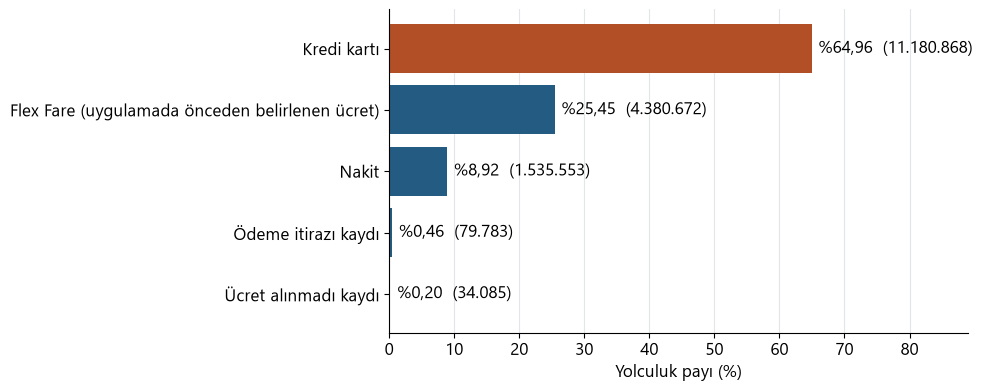

In [18]:
odeme_etiket = {
    0: "Flex Fare (uygulamada önceden belirlenen ücret)", 1: "Kredi kartı", 2: "Nakit",
    3: "Ücret alınmadı kaydı", 4: "Ödeme itirazı kaydı",
}
pay_view = payment.assign(etiket=payment["payment_type"].map(odeme_etiket)).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.7, 3.8), layout="constrained")
bars = ax.barh(pay_view["etiket"], pay_view["share_pct"],
               color=[ORANGE if k == 1 else BLUE for k in pay_view["payment_type"]])
ax.bar_label(bars, labels=[f"%{tr_dec(r.share_pct)}  ({tr_int(r.trip_count)})"
                           for r in pay_view.itertuples()], padding=5)
ax.set(xlim=(0, 89), xlabel="Yolculuk payı (%)")
ax.grid(axis="x")
show_figure(fig)


| TLC kodu | Kullanım durumu |
| --- | --- |
| **0 — Flex Fare** | TLC’nin resmî Flex Fare kategorisidir. Lisanslı taksi uygulaması yolculuktan önce bağlayıcı bir fiyat sunar. |
| **1 — Credit card** | Ödeme kart işlemi olarak kaydedilir. |
| **2 — Cash** | Ödeme nakit kaydedilir. Kart işlemi başarısız olursa yolcu başka kart veya nakit kullanabilir. |
| **3 — No charge** | Ücret alınmadı olarak işaretlenmiş kayıttır. TLC toplantı tutanağındaki bir sürücü örneğinde yolcu ödeme yapmadan araçtan inmiştir. |
| **4 — Dispute** | Ücret veya ödeme uyuşmazlığı olarak işaretlenmiş kayıttır. Örneğin yolcu talep edilen tutara itiraz edebilir. |
| **5 — Unknown / 6 — Voided trip** | Ödeme biçiminin bilinmediği veya kaydın iptal edildiği durumlardır. Bu temiz veri döneminde görünmez. |

**Kod 3 ve 4:** Temiz veride sırasıyla **34.085** ve **79.783** kayıt var. Bu kayıtların hepsinde `total_amount` pozitif. Temizlik kuralı sıfır ve negatif tutarları kapsam dışı bıraktı. TLC, ödeme reddedilse bile taksimetredeki tutarın kayıt altına alınmasını öngörüyor. Kod ve kayıtlı tutar, ödeme yapılmamasının sebebini ya da itirazın sonucunu açıklamaz. [TLC veri sözlüğü](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf) · [TLC Flex Fare tanımı](https://www.nyc.gov/site/tlc/businesses/e-hail-providers.page) · [TLC sürücü kuralları §80-17](https://www.nyc.gov/assets/tlc/downloads/pdf/rule_book_current_chapter_80.pdf) · [TLC toplantı tutanağı](https://www.nyc.gov/assets/tlc/downloads/About/commission_meeting_transcript/transcript_04_25_2019.pdf) · [TLC yolcu SSS](https://www.nyc.gov/site/tlc/passengers/passenger-frequently-asked-questions.page)

### Ödeme payı, kart tutarı ve kayıtlı bahşiş

**Ödeme payı nasıl çıkıyor?** `groupBy("payment_type")` kayıtları beş ödeme satırına özetler. Ardından `sum("trip_count").over(Window.partitionBy())` bu beş satırın tamamından ortak paydayı hesaplar ve her ödeme satırına ekler. Boş `partitionBy()` beş özet satırını tek pencereye alır. Bu adım, ham yolculuk satırları gruplandıktan sonra çalışır.

| Kredi kartı satırı | Beş ödeme satırının toplamı | Kredi kartının yolculuk payı |
| ---: | ---: | ---: |
| 11.180.868 yolculuk | 17.210.961 yolculuk | %64,96 |

Kart kategorisinde ortalama `total_amount` **29,05 USD**. Pozitif temel ücretli ve kayıtlı bahşişi sıfır veya üstü olan **11.180.868** kart kaydında, **toplam kayıtlı bahşiş ÷ toplam temel ücret = %23,50**. Nakit bahşiş TLC tarafından bu veri alanında kaydedilmez. [TLC tutar ve bahşiş alanları sözlüğü](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)

In [19]:
odeme_tablosu = pd.DataFrame({
    "TLC kodu": payment["payment_type"],
    "Kategori": payment["payment_type"].map(odeme_etiket),
    "Yolculuk": payment["trip_count"].map(tr_int),
    "Yolculuk payı": payment["share_pct"].map(lambda v: "%" + tr_dec(v)),
    "Ort. kayıtlı toplam tutar (USD)": payment["mean_total_amount"].map(tr_dec),
    "Bahşiş hesabına giren kayıt": payment["tip_eligible_trips"].map(tr_int),
    "Ağırlıklı kayıtlı bahşiş": payment["weighted_tip_pct"].map(lambda v: "—" if pd.isna(v) else "%" + tr_dec(v)),
})
display(odeme_tablosu.set_index("TLC kodu"))


,Kategori,Yolculuk,Yolculuk payı,Ort. kayıtlı toplam tutar (USD),Bahşiş hesabına giren kayıt,Ağırlıklı kayıtlı bahşiş
TLC kodu,,,,,,
1,Kredi kartı,11.180.868,"%64,96","29,05",11.180.868,"%23,50"
0,Flex Fare (uygulamada önceden belirlenen ücret),4.380.672,"%25,45","32,63",0,—
2,Nakit,1.535.553,"%8,92","24,87",0,—
4,Ödeme itirazı kaydı,79.783,"%0,46","27,76",0,—
3,Ücret alınmadı kaydı,34.085,"%0,20","23,93",0,—


In [20]:
sorgulari_goster([spark_queries.payment_trip_counts], [kiyas.pandas_payments])

**PySpark**

```python
def payment_trip_counts(trips: DataFrame) -> DataFrame:
    """Count payment codes and calculate their share of all pickups."""
    labels = F.create_map(
        F.lit(0), F.lit("Flex Fare"),
        F.lit(1), F.lit("Credit card"),
        F.lit(2), F.lit("Cash"),
        F.lit(3), F.lit("No charge"),
        F.lit(4), F.lit("Dispute"),
        F.lit(5), F.lit("Unknown"),
        F.lit(6), F.lit("Voided trip"),
    )
    eligible = (F.col("payment_type") == 1) & (F.col("fare_amount") > 0) & (F.col("tip_amount") >= 0)
    counts = trips.groupBy("payment_type").agg(
        F.count("*").alias("trip_count"),
        F.avg("total_amount").alias("mean_total_amount"),
        F.count(F.when(eligible, 1)).alias("tip_eligible_trips"),
        F.sum(F.when(eligible, F.col("tip_amount"))).alias("eligible_tip_total"),
        F.sum(F.when(eligible, F.col("fare_amount"))).alias("eligible_fare_total"),
    )
    return (
        counts.withColumn("payment_label", labels[F.col("payment_type").cast("int")])
        .withColumn("share_pct", 100.0 * F.col("trip_count") / F.sum("trip_count").over(Window.partitionBy()))
        .withColumn("weighted_tip_pct", F.when(F.col("eligible_fare_total") > 0,
                    100.0 * F.col("eligible_tip_total") / F.col("eligible_fare_total")))
        .drop("eligible_tip_total", "eligible_fare_total")
        .orderBy(F.desc("trip_count"), F.asc("payment_type"))
    )
```

**pandas**

```python
def pandas_payments(trips):
    eligible = (trips["payment_type"].eq(1) & trips["fare_amount"].gt(0)
                & trips["tip_amount"].ge(0))
    card = trips.loc[eligible, ["payment_type", "tip_amount", "fare_amount"]]
    card_stats = card.groupby("payment_type").agg(
        tip_eligible_trips=("tip_amount", "size"),
        eligible_tip_total=("tip_amount", "sum"),
        eligible_fare_total=("fare_amount", "sum"),
    )
    counts = trips.groupby("payment_type", dropna=False).agg(
        trip_count=("total_amount", "size"),
        mean_total_amount=("total_amount", "mean"),
    ).join(card_stats)
    fare = counts["eligible_fare_total"]
    return (counts.assign(
        tip_eligible_trips=counts["tip_eligible_trips"].fillna(0).astype("int64"),
        payment_label=counts.index.map(PAYMENT_LABELS),
        share_pct=100 * counts["trip_count"] / counts["trip_count"].sum(),
        weighted_tip_pct=100 * counts["eligible_tip_total"] / fare.where(fare.gt(0)),
    ).drop(columns=["eligible_tip_total", "eligible_fare_total"])
      .reset_index().sort_values(["trip_count", "payment_type"], ascending=[False, True]))
```

## Sonuç kontrolü

İki yöntem aynı beş temiz Parquet dosyasını, sekiz gerekli sütunu ve TLC bölge sözlüğünü kullanır. Altı sonuç tablosunun sütunları, satır sırası, boş değerleri ve sayıları karşılaştırılır. Ondalık değerler toleransla kontrol edilir.


In [21]:
display(pd.DataFrame([
    {"Özet": title, "PySpark satırı": len(spark_tables[name]),
     "pandas satırı": len(pandas_tables[name]), "Doğrulama": "Eşleşti"}
    for name, title in kiyas.SUMMARY_NAMES.items()
]).set_index("Özet"))


,PySpark satırı,pandas satırı,Doğrulama
Özet,,,
Saat,24,24,Eşleşti
Gün ve pencere,151,151,Eşleşti
Hafta günü × saat,168,168,Eşleşti
Biniş bölgesi,260,260,Eşleşti
İlçede %80 eşiği,5,5,Eşleşti
Ödeme,5,5,Eşleşti


### Aynı altı kayıt iki yöntemde nasıl sayılıyor?

**Spark'sız Python:** PyArrow, Parquet'ten gerekli sütunları okur. pandas tek Python sürecinde sayımları, birleşimleri ve pencere hesaplarını yapar.

**PySpark:** Veri parçaları üzerinde ara sayımlar yapılır. `Exchange` aynı saate ait ara sonuçları bir araya getirir. Son gruplama saat başına bir sonuç üretir. Aşağıdaki A ve B iki öğretici veri parçasıdır. [Spark çalışma kılavuzu](https://spark.apache.org/docs/3.5.9/rdd-programming-guide.html#shuffle-operations)

Plan tablosu sekiz sütunlu önbellekten saat sayımının nasıl üretildiğini gösterir. Saat sorgusu önbellekten yalnızca saat sütununu kullanır.

A parçası **18.00 için 2**, B parçası aynı saat için **1** biniş sayar. Spark, `Exchange` adımında aynı saate ait ara sayımları bir araya getirir. Son gruplama **18.00 için 3 biniş** verir. İki parça yerel çalışmanın öğretici örneğidir.

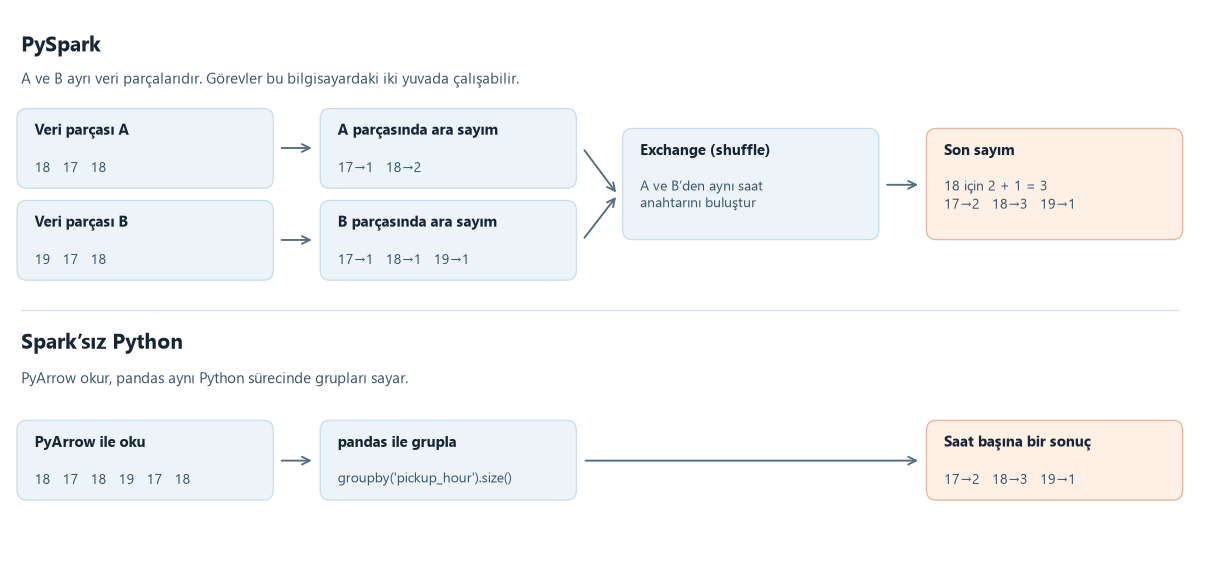

In [22]:
from collections import Counter
from matplotlib.patches import FancyBboxPatch

parca_a, parca_b = ornek_saatler[:3], ornek_saatler[3:]
ara_a, ara_b = Counter(parca_a), Counter(parca_b)
assert dict(ara_a + ara_b) == ornek_gruplar.to_dict()

def kodlari_yaz(hours):
    return "   ".join(map(str, hours))

def adetleri_yaz(counts):
    return "   ".join(f"{h}→{n}" for h, n in sorted(counts.items()))

fig, ax = plt.subplots(figsize=(12.0, 5.6), layout="constrained")
ax.set(xlim=(0, 16), ylim=(0, 7.2))
ax.set_axis_off()

def adim(x, y, title, body, height=.93, fill="#EDF4F9", edge="#CCDEE9"):
    ax.add_patch(FancyBboxPatch((x, y), 3.33, height,
                                boxstyle="round,pad=.055,rounding_size=.13",
                                facecolor=fill, edgecolor=edge, linewidth=1))
    ax.text(x + .18, y + height - .24, title, fontsize=11, weight="bold",
            color="#172637", va="center")
    ax.text(x + .18, y + height - .60, body, fontsize=10.25, color="#36536A",
            va="top", linespacing=1.25)

def bagla(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops={"arrowstyle": "->", "lw": 1.35, "color": "#536D82", "mutation_scale": 14})

ax.text(.15, 6.65, "PySpark", fontsize=15, weight="bold", color="#172637")
ax.text(.15, 6.23, "A ve B ayrı veri parçalarıdır. Görevler bu bilgisayardaki iki yuvada çalışabilir.",
        fontsize=10.7, color="#36536A")
for letter, y, rows, counts in (("A", 4.92, parca_a, ara_a), ("B", 3.72, parca_b, ara_b)):
    adim(.15, y, f"Veri parçası {letter}", kodlari_yaz(rows))
    adim(4.22, y, f"{letter} parçasında ara sayım", adetleri_yaz(counts))
    bagla(3.61, y + .47, 4.09, y + .47)
    bagla(7.69, y + .47, 8.16, 4.78)
adim(8.28, 4.25, "Exchange (shuffle)", "A ve B’den aynı saat\nanahtarını buluştur", height=1.34)
adim(12.36, 4.25, "Son sayım", f"18 için 2 + 1 = 3\n{adetleri_yaz(ornek_gruplar)}",
     height=1.34, fill="#FFF0E6", edge="#E4B9A1")
bagla(11.74, 4.91, 12.23, 4.91)

ax.plot([.15, 15.7], [3.28, 3.28], color="#D7E2EA", linewidth=.9)
ax.text(.15, 2.77, "Spark’sız Python", fontsize=15, weight="bold", color="#172637")
ax.text(.15, 2.32, "PyArrow okur, pandas aynı Python sürecinde grupları sayar.",
        fontsize=10.7, color="#36536A")
adim(.15, .85, "PyArrow ile oku", kodlari_yaz(ornek_saatler))
adim(4.22, .85, "pandas ile grupla", "groupby('pickup_hour').size()")
adim(12.36, .85, "Saat başına bir sonuç", adetleri_yaz(ornek_gruplar),
     fill="#FFF0E6", edge="#E4B9A1")
bagla(3.61, 1.31, 4.09, 1.31)
bagla(7.69, 1.31, 12.23, 1.31)
show_figure(fig)


In [23]:
for label in ("InMemoryTableScan", "partial_count", "hashpartitioning", "HashAggregate", "Sort ["):
    assert any(label in line for line in spark_plan), label
assert any("HashAggregate" in line and "partial_count" not in line for line in spark_plan)

operators = []
for line in reversed(spark_plan):
    if "FileScan parquet" in line:
        operators.append(("Parquet taraması", "Sekiz gerekli sütun tekrar kullanım için seçilir."))
    elif "InMemoryTableScan" in line:
        operators.append(("InMemoryTableScan", "Saat sorgusu önbellekten saat sütununu alır."))
    elif "partial_count" in line:
        operators.append(("HashAggregate / partial_count", "Her parçada saatlere göre ara sayım yapılır."))
    elif "hashpartitioning" in line:
        operators.append(("Exchange / hashpartitioning", "Aynı saatin ara sayımları bir araya gönderilir."))
    elif "HashAggregate" in line:
        operators.append(("HashAggregate / son sayım", "Her saat için ara sayımlar toplanır."))
    elif "Sort [" in line:
        operators.append(("Sort", "Sonuçlar biniş sayısı ve saat ile sıralanır."))
display(pd.DataFrame(operators, columns=["Gerçek Spark planındaki işlem", "Ne yapıyor?"]).set_index(
    "Gerçek Spark planındaki işlem"))


,Ne yapıyor?
Gerçek Spark planındaki işlem,
Parquet taraması,Sekiz gerekli sütun tekrar kullanım için seçilir.
InMemoryTableScan,Saat sorgusu önbellekten saat sütununu alır.
HashAggregate / partial_count,Her parçada saatlere göre ara sayım yapılır.
Exchange / hashpartitioning,Aynı saatin ara sayımları bir araya gönderilir.
HashAggregate / son sayım,Her saat için ara sayımlar toplanır.
Sort,Sonuçlar biniş sayısı ve saat ile sıralanır.


### Sonuçları derste nasıl göstereceğim?

| Soru | Notebook’ta gösterilecek kanıt |
| --- | --- |
| Gruplama ve pencerenin farkı ne? | Altı biniş üç saat grubuna iner. Yedi günlük pencere 151 tarih satırını korur. |
| 25 Nisan neden dikkat çekiyor? | Önce 153.232 binişi ve üç cumartesi karşılaştırmasını, sonra artışın saat ve bölgelere dağılımını göster. Etkinlik ve yağış, o güne ait doğrulanmış bağlamdır. |
| İki yöntem aynı işi yaptı mı? | Altı çıktı tablosunun eşitlik kontrolünü göster. |